Name Haoxin Ni

Labpartner(s)

In [1]:
# Imports for the warmup
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


# Class 8.1

Today we are presenting movies! The homework is to work on your proposals. 


**W.1** This week our warmups are focused on applying your Pandas skills. Please download the 2026 World Cup player stats from slack (pinned to #announcements), and do some analyisis on this, whatever you are keen on. We'll do more with this on Wednesday. Show your work and make sure you write some text about what you found. 

### W.1: Playing time and scoring

In [2]:
# Read the CSV from either the week8 notebook folder or the project root.
data_path = Path('player_stats.csv')
if not data_path.exists():
    data_path = Path('week8/player_stats.csv')
players = pd.read_csv(data_path)

print(f'Players: {len(players):,}; teams: {players["team_id"].nunique()}')
print(f'Duplicate player IDs: {players["player_id"].duplicated().sum()}')
print(f'Players with zero minutes: {players["minutes_played"].eq(0).sum()}')
display(players.head())

# Inspect missing values before choosing which columns to analyze.
missing = players.isna().sum()
display(missing[missing > 0].rename('missing_values').to_frame())

Players: 1,248; teams: 48
Duplicate player IDs: 0
Players with zero minutes: 209


,player_id,player_name,team_id,position,matches_played,matches_started,minutes_played,goals,assists,shots,...,yellow_cards,red_cards,penalty_goals,own_goals,clean_sheets,saves,goals_conceded,average_rating,data_source,last_verified
0,1,José Raúl Rangel,1,GK,5,5,438,0,0,NaN,...,0,0,0,0,4.0,7.0,3.0,NaN,sofascore.com,2026-07-19
1,2,Jorge Eduardo Sanchez,1,DEF,5,5,439,0,1,NaN,...,0,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
2,3,César Jasib Montes,1,DEF,3,2,165,0,0,NaN,...,0,1,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
3,4,Edson Omar Alvarez,1,DEF,2,0,75,0,0,NaN,...,1,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
4,5,Johan Felipe Vasquez,1,DEF,2,2,180,0,0,NaN,...,0,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19


,missing_values
shots,1248
shots_on_target,1248
clean_sheets,1103
saves,1103
goals_conceded,1103
average_rating,1248
data_source,209


### Highest goal totals

In [3]:
scorer_columns = ['player_name', 'team_id', 'position',
                  'minutes_played', 'goals', 'assists']
top_scorers = players.sort_values(
    ['goals', 'assists', 'player_id'], ascending=[False, False, True]
).head(10)
display(top_scorers[scorer_columns].reset_index(drop=True))

,player_name,team_id,position,minutes_played,goals,assists
0,Kylian Mbappe,33,FWD,711,10,4
1,Lionel Andrés Messi,37,FWD,590,8,4
2,Jude Victor William Bellingham,45,MID,596,7,1
3,Erling Braut Haaland,36,FWD,450,7,0
4,Harry Edward Kane,45,FWD,534,6,1
5,Masour Ousmane Dembele,33,FWD,363,5,2
6,Mikel Oyarzabal,29,FWD,394,5,1
7,Julián Andrés Quinones,1,FWD,221,4,1
8,José Vinicius,9,FWD,441,4,1
9,Bradley Jean-Manuel Essolisa Barcola,33,FWD,283,4,1


### Most minutes within each team

In [4]:
team_max_minutes = players.groupby('team_id')['minutes_played'].transform('max')
most_minutes = players.loc[
    players['minutes_played'].eq(team_max_minutes),
    ['team_id', 'player_name', 'position', 'matches_played', 'minutes_played']
].sort_values(['team_id', 'player_name']).reset_index(drop=True)

leader_counts = most_minutes.groupby('team_id').size()
print(f'{len(most_minutes)} leaders across {len(leader_counts)} teams')
print(f'Teams with tied leaders: {(leader_counts > 1).sum()}')
display(most_minutes.head(15))

print('Highest minutes overall:')
display(players.nlargest(5, 'minutes_played')[
    ['player_name', 'team_id', 'position', 'minutes_played']
].reset_index(drop=True))

123 leaders across 48 teams
Teams with tied leaders: 36


,team_id,player_name,position,matches_played,minutes_played
0,1,Erik Antonio Lira,MID,5,450
1,1,Jesús Daniel Gallardo,DEF,5,450
2,2,Ime Daniel Okon,DEF,4,360
3,2,Khuliso Johnson Mudau,DEF,4,360
4,2,Mbekezeli Mfanufikile Mbokazi,DEF,4,360
5,2,Ronwen Hayden Williams,GK,4,360
6,3,Gihyuk Lee,MID,3,270
7,3,Hanbeom Lee,DEF,3,270
8,3,Kangin Lee,MID,3,270
9,3,Seunggyu Kim,GK,3,270


Highest minutes overall:


,player_name,team_id,position,minutes_played
0,Marc Cucurella,29,DEF,750
1,Alexis Mac Allister,37,MID,720
2,Kylian Mbappe,33,FWD,711
3,Michael Akpovie Olise,33,FWD,668
4,Enzo Jeremías Fernandez,37,MID,663


### Scoring by position

,players,total_minutes,total_goals,total_assists,goals_per_90
position,,,,,
GK,145,19379,0,1,0.000
DEF,421,78516,29,36,0.033
MID,369,67375,93,75,0.124
FWD,313,45639,172,92,0.339


Forwards scored 58.5% of recorded player goals.


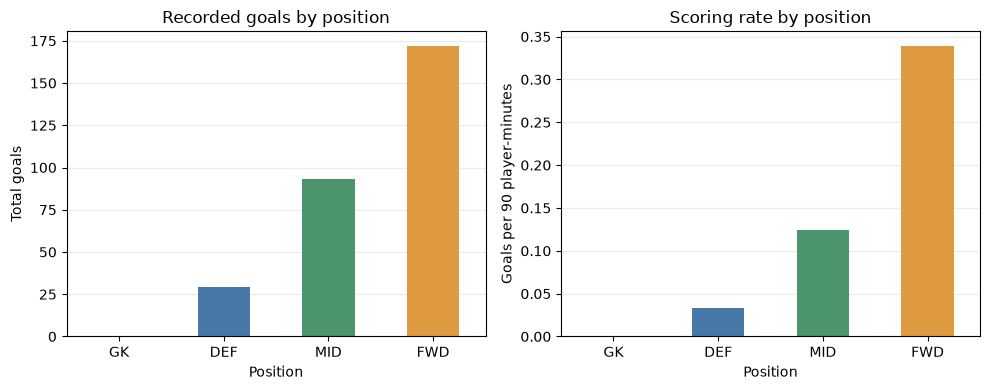

In [5]:
position_order = ['GK', 'DEF', 'MID', 'FWD']
position_summary = players.groupby('position').agg(
    players=('player_id', 'count'),
    total_minutes=('minutes_played', 'sum'),
    total_goals=('goals', 'sum'),
    total_assists=('assists', 'sum')
).reindex(position_order)
position_summary['goals_per_90'] = (
    90 * position_summary['total_goals']
    / position_summary['total_minutes'].replace(0, float('nan'))
)
display(position_summary.round(3))

forward_share = (
    position_summary.loc['FWD', 'total_goals'] / players['goals'].sum()
)
print(f'Forwards scored {forward_share:.1%} of recorded player goals.')

# Compare both the total goals and the rate adjusted for playing time.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
colors = ['#8b9dab', '#4878a8', '#4c956c', '#df9a3f']
position_summary['total_goals'].plot.bar(ax=axes[0], color=colors, rot=0)
position_summary['goals_per_90'].plot.bar(ax=axes[1], color=colors, rot=0)
axes[0].set(title='Recorded goals by position', ylabel='Total goals')
axes[1].set(title='Scoring rate by position', ylabel='Goals per 90 player-minutes')
for ax in axes:
    ax.set_xlabel('Position')
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
plt.show()

### What I found

The supplied dataset contains **1,248 players from 48 teams**, including
**209 players with zero recorded minutes**. Player IDs are unique. In this
file, **Kylian Mbappe** has the highest goal total with **10 goals and 4 assists
in 711 minutes**. Lionel Andrés Messi follows with 8 goals. **Marc Cucurella**
has the most recorded playing time overall at **750 minutes**.

There are **123 players tied for their team's highest minutes**, and **36 of
48 teams** have multiple leaders. For example, team 1 has Erik Antonio Lira
and Jesús Daniel Gallardo tied at 450 minutes. Keeping ties gives a more
complete answer than selecting only the first maximum for each team.

Forwards scored **172 of the 294 recorded player goals (58.5%)**. Their pooled
rate is **0.339 goals per 90 player-minutes**, compared with **0.124 for
midfielders**, **0.033 for defenders**, and **0.000 for goalkeepers**. Forwards
have fewer total minutes than midfielders and defenders but score more goals,
so their lead remains after adjusting for playing time.

These findings describe the supplied CSV. Raw totals depend on how much a
player played and how far a team progressed, and position affects a player's
role. The file has no values for `shots`, `shots_on_target`, or `average_rating`,
so it cannot support shot-conversion or rating comparisons. Goalkeeper-specific
columns are mostly missing for other positions. Some names appear duplicated
within a name or unusually formatted, so I retained the supplied names and
used player IDs for identity rather than guessing corrections.

### Questions

# Lab 8.1

**E.0** Complete the previous labs if you are behind.

**E.1** Sign up for an LSU HPC account:

Each student should submit an HPC account request through the LSU HPC account request portal https://accounts.hpc.lsu.edu/login_request.php. In the Account Sponsor field, use my name and email address as your sponsor. 

We will be going over how to use the LSU HPC in the coming weeks. 


**E.2** Create an outline for your research proposal. Review the proposal rubric and create an outline for how you will meet all the grading criteria. Turn this in on Moodle, due by Wed Oct 14 midnight. 

### Research proposal outline

**Evaluating Tropical Cyclone Tracks with TempestExtremes**

Haoxin Ni - 18 October 2026

[Editable Word version](../final_project/Haoxin_Ni_Proposal_Outline.docx) | [PDF for submission](../final_project/Haoxin_Ni_Proposal_Outline.pdf)

#### Project summary

I will evaluate how TempestExtremes tracks three 2021 Atlantic storms, Ida, Larry, and Nicholas, in ERA5 reanalysis. I will compare the detected tracks with IBTrACS and test whether changing the pressure contour threshold affects track recovery and position differences. The goal is a reproducible case study of tracking sensitivity.

#### Motivation

Automated tracking makes large weather datasets easier to analyze, but its results depend on detection and linking criteria [1, 2]. Comparing several contrasting storms with a documented reference will help identify where a chosen configuration works and where it misses part of a storm. This is a small methods project rather than a basin-wide accuracy assessment.

#### Research questions and hypothesis

- R1. How closely do the baseline TE tracks follow IBTrACS positions, and which parts of each reference track are recovered?

- R2. How do pressure contour thresholds of 1, 2, and 3 hPa change recovery and position differences when the other settings remain fixed?

Hypothesis: a weaker threshold may recover more weak or early-stage positions, while a stronger threshold may omit them. Any gain in recovery may come with more ambiguous candidate tracks.

#### Data and methods

- Data preparation. Use the downloaded ERA5 fields for 24 August-17 September 2021, at six-hourly times over 0-70 N and 110 W-10 E [3]. Inputs include sea-level pressure, 10-m winds, geopotential at 300 and 500 hPa, and surface geopotential. Use IBTrACS v04r01 for the three reference tracks [4, 5]. Standardize UTC times, coordinates, and units with xarray and Pandas.

- Detection and tracking. Extend the existing Python workflow into a parameterized runner for TE DetectNodes and StitchNodes using the published ERA5 recipe [1]. Compare 1-, 2-, and 3-hPa pressure contour thresholds while fixing other settings, including the 54-hour minimum duration and 24-hour maximum gap. Save commands, software version, logs, and outputs separately for each configuration.

- Evaluation of R1 and R2. Write reusable functions to match six-hourly timestamps and calculate great-circle separation. Fix reference windows before comparing settings. Require at least three pairs within 300 km to associate a track; select the track with most matches, breaking ties by median separation. Report coverage as matched/reference positions, plus mean and median matched separation. Combine the nine storm-configuration comparisons into one table.

- Reproducibility. Check coordinates, units, missing and duplicate times, and distance calculations. Inspect missed times and ambiguous associations. Preserve scripts, settings, logs, tables, and figures, and document AI coding assistance. Other regional tracks will not automatically count as false alarms.

#### Preliminary work and figure plan

The existing Ida trial recovered 24 of 26 reference positions (92.3%) during 26 August-1 September, with mean matched separation of 26.0 km. This establishes feasibility for this window; the other storms and threshold experiments remain planned work.

Proposal figures: the study region with three IBTrACS reference tracks, and the existing Ida comparison map with its separation time series. Both have been generated for the formal proposal with captions and text references.

Final report figure plan: six figures generated in Python, using storm panels where appropriate.

- Figure 1. Study region and the three IBTrACS reference tracks.

- Figure 2. Baseline TE and reference paths for all three storms (R1).

- Figure 3. Baseline position separation through time for each storm (R1).

- Figure 4. Coverage across storms and pressure thresholds (R2).

- Figure 5. Mean and median matched separation across thresholds (R2).

- Figure 6. Matched and missed reference times under each threshold (R2).

#### Expected contribution and limits

I expect to produce a reproducible comparison of tracking settings and explain missed or displaced segments. This supports transparent use of cyclone tracks in climate and hazard research. Three storms, regional boundaries, and ERA5 resolution limit generalization; gridded ERA5 winds and IBTrACS sustained winds are not interchangeable. Final deliverables will include an 8-12-page scientific report with six Python figures and cleaned analysis code saved on GitHub and linked in the report.

#### Timeline

19-25 October: finalize the proposal and reference windows. 26 October-8 November: extend baseline tracking and matching to Larry and Nicholas. 9-22 November: run all three thresholds and verify comparisons. 23 November-6 December: produce the six final figures and draft the report. 7-10 December: rerun checks and revise. Complete these experiments before considering extra parameters.

#### Initial references

[1] Ullrich, P. A., et al. (2021). TempestExtremes v2.1: a community framework for feature detection, tracking, and analysis in large datasets. Geoscientific Model Development, 14, 5023-5048. https://doi.org/10.5194/gmd-14-5023-2021

[2] Zarzycki, C. M., and Ullrich, P. A. (2017). Assessing sensitivities in algorithmic detection of tropical cyclones in climate data. Geophysical Research Letters, 44, 1141-1149. https://doi.org/10.1002/2016GL071606

[3] Hersbach, H., et al. (2020). The ERA5 global reanalysis. Quarterly Journal of the Royal Meteorological Society, 146, 1999-2049. https://doi.org/10.1002/qj.3803

[4] Knapp, K. R., et al. (2010). The International Best Track Archive for Climate Stewardship (IBTrACS): Unifying tropical cyclone data. Bulletin of the American Meteorological Society, 91, 363-376. https://doi.org/10.1175/2009BAMS2755.1

[5] Gahtan, J., et al. (2024). International Best Track Archive for Climate Stewardship (IBTrACS) Project, Version 4.01. NOAA NCEI. Subset: Ida, Larry, and Nicholas, 2021; downloaded 11 October 2026. https://doi.org/10.25921/82ty-9e16

**E.3** (Optional) Explore methods related to your final project, for example by exploring tutorials on datacamp or other resources.

### E.3: Time series methods for the Hurricane Ida project

Completed on **October 14, 2026**: Chapter 1, **Working with Time Series in
Pandas**, of DataCamp's
[Manipulating Time Series Data in Python](https://app.datacamp.com/learn/courses/manipulating-time-series-data-in-python).
The chapter shows **100% completion**. The lessons and exercises were completed
with AI assistance, using the lesson transcripts and exercise feedback.

The chapter covered date ranges, converting strings to dates, setting a
`DatetimeIndex`, selecting time intervals, changing frequency with `asfreq()`,
and calculating changes with `shift()`, `diff()`, and `pct_change()`.

These methods are useful for my final project because TempestExtremes tracks
and IBTrACS observations must be organized by time before they can be compared.
I applied the date-indexing and difference methods to the existing Hurricane
Ida track from the TempestExtremes baseline run. The source is
`final_project/outputs/te_ida_baseline/ida_te_track.csv`; a copy is included in
`lab81_resources/ida_te_track.csv` so this lab can run without repeating the
tracking calculation. Times are UTC, sea-level pressure is stored in Pa, and
wind speed is stored in m/s.

In [6]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the accompanying data when running from week8 or the project root.
lab_folder = Path('.') if Path('lab81_resources').is_dir() else Path('week8')
ida = pd.read_csv(lab_folder / 'lab81_resources/ida_te_track.csv')
ida['time'] = pd.to_datetime(ida['time'], utc=True)
ida = ida.set_index('time').sort_index()

# A single track and unique timestamps are needed before regularizing time.
assert ida['track_id'].nunique() == 1
assert ida.index.is_unique
ida['slp_hpa'] = ida['slp'] / 100  # 100 Pa = 1 hPa

print(f'Track points: {len(ida)}')
print(f'Time range (UTC): {ida.index.min()} to {ida.index.max()}')
print('Time intervals between successive observations:')
display(ida.index.to_series().diff().value_counts().rename('count').to_frame())

# Use a six-hour grid. Missing observations remain NaN.
ida_6h = ida[['slp_hpa', 'wind']].asfreq('6h')
ida_6h['previous_slp_hpa'] = ida_6h['slp_hpa'].shift(1)
ida_6h['slp_change_6h_hpa'] = ida_6h['slp_hpa'].diff(1)
print(f'Missing pressure values on the six-hour grid: {ida_6h["slp_hpa"].isna().sum()}')

# A partial-date slice includes every six-hour record on the end date.
landfall_window = ida_6h.loc['2021-08-28':'2021-08-30'].copy()
display(landfall_window.round(2))

minimum_time = ida_6h['slp_hpa'].idxmin()
print(f'Lowest modeled track pressure: {ida_6h.loc[minimum_time, "slp_hpa"]:.2f} hPa at {minimum_time}')

Track points: 28
Time range (UTC): 2021-08-27 00:00:00+00:00 to 2021-09-02 18:00:00+00:00
Time intervals between successive observations:


,count
time,
0 days 06:00:00,27


Missing pressure values on the six-hour grid: 0


,slp_hpa,wind,previous_slp_hpa,slp_change_6h_hpa
time,,,,
2021-08-28 00:00:00+00:00,999.03,22.15,997.16,1.87
2021-08-28 06:00:00+00:00,998.11,23.49,999.03,-0.92
2021-08-28 12:00:00+00:00,995.72,24.13,998.11,-2.39
2021-08-28 18:00:00+00:00,991.60,22.00,995.72,-4.12
2021-08-29 00:00:00+00:00,989.09,25.64,991.60,-2.51
2021-08-29 06:00:00+00:00,989.65,25.23,989.09,0.56
2021-08-29 12:00:00+00:00,985.28,30.35,989.65,-4.37
2021-08-29 18:00:00+00:00,982.17,29.60,985.28,-3.11
2021-08-30 00:00:00+00:00,981.85,27.58,982.17,-0.32


Lowest modeled track pressure: 981.85 hPa at 2021-08-30 00:00:00+00:00


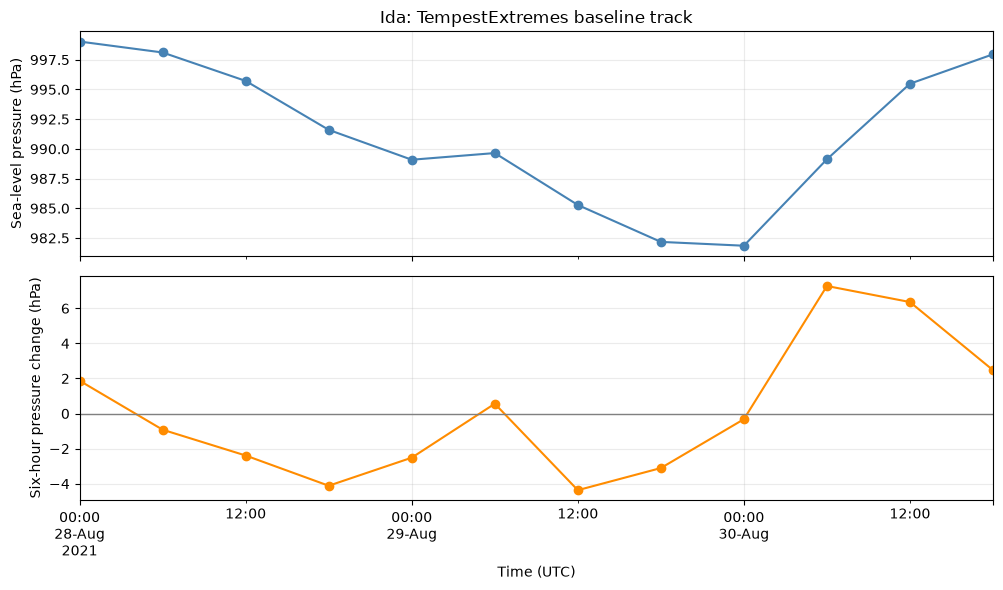

In [7]:
# Plot pressure and its six-hour change in separate panels with their units.
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
landfall_window['slp_hpa'].plot(ax=axes[0], marker='o', color='steelblue')
landfall_window['slp_change_6h_hpa'].plot(ax=axes[1], marker='o', color='darkorange')
axes[0].set(title='Ida: TempestExtremes baseline track', ylabel='Sea-level pressure (hPa)')
axes[1].set(ylabel='Six-hour pressure change (hPa)', xlabel='Time (UTC)')
axes[1].axhline(0, color='gray', linewidth=1)
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

### Findings and project use

The Ida track contains **28 points**, from **August 27, 2021 at 00:00 UTC** to
**September 2 at 18:00 UTC**. All 27 successive intervals are six hours, and
there are no missing pressure values on that grid. In this modeled track,
the lowest sea-level pressure is **981.85 hPa at August 30, 00:00 UTC**.
Pressure falls through most of the selected August 28–30 window and then
rises after this minimum. Negative six-hour differences indicate falling
pressure; positive differences indicate rising pressure.

This is a diagnostic of the existing ERA5-based track. It is not an observed
best-track minimum. For a comparison with IBTrACS, I would align both datasets
in UTC and retain unmatched times as missing. A row difference represents six
hours only after checking or enforcing the six-hour grid. `asfreq('6h')`
selects values on that grid; it does not average values or invent observations.

**E.4** Make notes for yourself on progamming tecniques and commands you learned in the this week, including examples, comments and explainitory text. You can do this here or in a separate notebook that you link to here. Basically, you are making a cheat sheet for yourself.

### E.4: Pandas and time series cheat sheet

Reference: DataCamp Chapter 1 linked in E.3, plus the Pandas analysis in this
week's warmup. The examples below use a small synthetic pressure series and
the supplied player dataset.

| Command | Purpose and reminder |
| --- | --- |
| `pd.read_csv(path)` | Read a CSV into a DataFrame. Use `parse_dates=['time']` when parsing dates on import. |
| `df.head()` / `df.tail()` | Inspect the first or last rows. |
| `df.info()` | Inspect column types and nonmissing counts. It prints its summary and returns `None`. |
| `pd.to_datetime(df['time'], utc=True)` | Convert date strings to timestamps using UTC for these project files. |
| `pd.date_range(start, periods=n, freq='6h')` | Create a regular sequence of six-hour timestamps. |
| `timestamp.dayofweek` / `timestamp.day_name()` | Obtain the weekday number (Monday = 0) or name. |
| `df.set_index('time').sort_index()` | Make time the index and order the observations chronologically. |
| `df.loc['2021-08-28':'2021-08-30']` | Select a time interval. Partial-date slicing includes the whole end date. |
| `df.asfreq('6h')` | Select a regular six-hour grid. New timestamps have missing values. |
| `s.shift(1)` | Put the previous row's value at the current row. `shift(-1)` uses the next row's value. |
| `s.diff(1)` | Calculate current value minus previous value. The first result is missing. |
| `s.pct_change(1, fill_method=None) * 100` | Calculate percentage change without filling missing values. The previous value must be nonzero. |
| `pd.concat([a, b], axis=1)` | Combine columns, aligning by index labels. `axis=0` stacks rows. |
| `df.reset_index(drop=True)` | Replace the index with row numbers and discard the old index. |
| `df.isna().sum()` | Count missing values by column. Missing values are different from zeros. |
| `df.sort_values('goals', ascending=False)` | Sort a column from largest to smallest. |
| `df.groupby('position').agg(...)` | Calculate summary statistics separately for each group. |
| `df.groupby('team_id')['minutes_played'].transform('max')` | Return each team's maximum for every row, so tied leaders can all be selected. |
| `df.plot(subplots=True)` | Plot each column in its own panel. Label units and call `plt.show()`. |

**Things to check:** sort time before shifting or differencing; inspect duplicate
timestamps; check the spacing between rows; keep pressure units consistent;
and label the time zone. On a six-hour grid, `diff(4)` spans 24 hours.

`asfreq('D')` selects daily grid values. To calculate a daily mean instead,
use `resample('D').mean()`; averaging is a different operation. The DataCamp
exercise uses the older monthly alias `M`; current Pandas versions use `ME`
for month-end frequency. Do not replace missing pressure or wind values with
zero. A negative shift exposes future values, so it needs care in forecasting.

In [8]:
# Small synthetic example for practicing date and time commands.
# These four pressures are illustrative, not measurements from the Ida track.
example_times = pd.date_range('2021-08-28', periods=4, freq='6h', tz='UTC')
example = pd.DataFrame({'slp_hpa': [1000.0, 996.0, 990.0, 994.0]}, index=example_times)
example.index.name = 'time'
example['previous_hpa'] = example['slp_hpa'].shift(1)
example['change_6h_hpa'] = example['slp_hpa'].diff(1)
example['change_pct'] = example['slp_hpa'].pct_change(fill_method=None) * 100

display(example.round(3))
print('Date information:', example_times[0].dayofweek, example_times[0].day_name())
print('Missing results at the start of the series:')
display(example.isna().sum().rename('missing_values').to_frame())

# Changing to three-hour frequency creates new rows with missing values.
example_3h = example[['slp_hpa']].asfreq('3h')
display(example_3h)

,slp_hpa,previous_hpa,change_6h_hpa,change_pct
time,,,,
2021-08-28 00:00:00+00:00,1000.0,NaN,NaN,NaN
2021-08-28 06:00:00+00:00,996.0,1000.0,-4.0,-0.400
2021-08-28 12:00:00+00:00,990.0,996.0,-6.0,-0.602
2021-08-28 18:00:00+00:00,994.0,990.0,4.0,0.404


Date information: 5 Saturday
Missing results at the start of the series:


,missing_values
slp_hpa,0
previous_hpa,1
change_6h_hpa,1
change_pct,1


,slp_hpa
time,
2021-08-28 00:00:00+00:00,1000.0
2021-08-28 03:00:00+00:00,NaN
2021-08-28 06:00:00+00:00,996.0
2021-08-28 09:00:00+00:00,NaN
2021-08-28 12:00:00+00:00,990.0
2021-08-28 15:00:00+00:00,NaN
2021-08-28 18:00:00+00:00,994.0


In [9]:
# Reusable groupby patterns from the warmup.
player_path = Path('player_stats.csv')
if not player_path.exists():
    player_path = Path('week8/player_stats.csv')
player_notes = pd.read_csv(player_path)

position_notes = player_notes.groupby('position').agg(
    players=('player_id', 'count'),
    goals=('goals', 'sum'),
    minutes=('minutes_played', 'sum')
)
display(position_notes)

# Keep every player tied for the most minutes in team 1.
max_by_team = player_notes.groupby('team_id')['minutes_played'].transform('max')
team1_leaders = player_notes.loc[
    player_notes['team_id'].eq(1) & player_notes['minutes_played'].eq(max_by_team),
    ['team_id', 'player_name', 'minutes_played']
]
display(team1_leaders.reset_index(drop=True))

,players,goals,minutes
position,,,
DEF,421,29,78516
FWD,313,172,45639
GK,145,0,19379
MID,369,93,67375


,team_id,player_name,minutes_played
0,1,Erik Antonio Lira,450
1,1,Jesús Daniel Gallardo,450


In the synthetic example, the six-hour pressure changes are **−4, −6, and
+4 hPa**. The first change is missing because there is no earlier value.
Changing from six-hour to three-hour frequency adds three missing rows; it
does not create measured pressures. In the real player data, both Erik Antonio
Lira and Jesús Daniel Gallardo are retained as team 1's leaders at 450 minutes.